# Análise exploratória de dados (EDA)

O diabetes é uma doença crônica grave na qual os indivíduos perdem a capacidade de regular efetivamente os níveis de glicose no sangue e pode levar a uma redução na qualidade de vida e na expectativa de vida.

O Sistema de Vigilância de Fatores de Risco Comportamentais (BRFSS) é uma pesquisa telefônica relacionada à saúde que é coletada anualmente pelo CDC (Centro de Controle e Prevenção de Doenças dos Estados Unidos). A cada ano, a pesquisa coleta respostas de milhares de americanos sobre comportamentos de risco relacionados à saúde, condições crônicas de saúde e o uso de serviços preventivos. Para este projeto, foi utilizado conjunto de dados disponível no Kaggle para o ano de 2015. 

https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset

Dicionário de variáveis:

- `Diabetes_binary`: 0 = sem diabetes, 1 = com diabetes
- `HighBP`: 0 = sem pressão alta, 1 = com pressão alta
- `HighChol`: 0 = sem colesterol alto, 1 = com colesterol alto
- `CholCheck`: 0 = não fez exame de colesterol na vida, 1 = fez exame de colesterol alguma vez
- `BMI`: Índice de Massa Corporal (IMC)
- `Smoker`: 0 = não fumante, 1 = fumante
- `Stroke`: 0 = sem histórico de AVC, 1 = com histórico de AVC
- `HeartDiseaseorAttack`: 0 = sem histórico de doença cardíaca ou ataque cardíaco, 1 = com histórico de doença cardíaca ou ataque cardíaco
- `PhysActivity`: 0 = não pratica atividade física, 1 = pratica atividade física
- `Fruits`: 0 = não consome frutas, 1 = consome frutas
- `Veggies`: 0 = não consome vegetais, 1 = consome vegetais
- `HvyAlcoholConsump`: 0 = não consome álcool em altas quantidades, 1 = consome álcool em altas quantidades
- `AnyHealthcare`: 0 = não tem plano de saúde, 1 = tem plano de saúde
- `NoDocbcCost`: 0 = não foi ao médico por questões financeiras, 1 = foi ao médico por questões financeiras (últimos 12 meses)
- `GenHlth`: Saúde geral (1 a 5) - 1 = Excelente, 2 = Muito boa, 3 = Boa, 4 = Aceitável, 5 = Ruim
- `MentHlth`: Nos últimos 30 dias, quantos dias a saúde mental não foi boa (0 a 30)
- `PhysHlth`: Nos últimos 30 dias, quantos dias a saúde física não foi boa (0 a 30)
- `DiffWalk`: 0 = não tem dificuldade para caminhar, 1 = tem dificuldade para caminhar
- `Sex`: 0 = feminino, 1 = masculino
- `Age`: Idade em faixas 1 = 18-24; 2 = 25-29; 3 = 30-34; 4 = 35-39; 5 = 40-44; 6 = 45-49; 7 = 50-54; 8 = 55-59; 9 = 60-64; 10 = 65-69; 11 = 70-74; 12 = 75-79; 13 = 80+
- `Education`: Níveis de ensino 1 = nunca frequentou a escola; 2 = escola primária; 3 = escola secundária incompleta ; 4 = escola secundária; 5 = faculdade incompleta ou curso técnico; 6 = completou faculdade ou diplomas superiores
- `Income`: Renda anual (dólares) em faixas 1 = < 10.000; 2 = 10.000-14.999; 3 = 15.000-19.999; 4 = 20.000-24.999; 5 = 25.000-34.999; 6 = 35.000-49.999; 7 = 50.000-74.999; 8 = 75.000+

## Importações

Todas as importações do notebook ficam concentradas nesta célula. O módulo `graficos` (material do curso) traz a função de gráficos usada neste notebook, e o `src.config` os caminhos dos dados.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency

from graficos import plotar_histogramas_preenchidos
from src.config import DADOS_TRATADOS

## Variáveis categóricas

## Carregando a base tratada

Lê o arquivo `.parquet` gerado no notebook 01.

In [2]:
df_diabetes_tratado = pd.read_parquet(DADOS_TRATADOS)

df_diabetes_tratado.head()

,Diabetes,PressaoAlta,ColesterolAlto,ColesterolExame,IMC,Fumante,AVC,ProblemaCardiaco,AtividadeFisica,ComeFrutas,...,PlanoSaude,SemDinheiroConsultas,SaudeGeral,DiasProblemasMentais,DiasProblemasFisicos,DificuldadeAndar,Sexo,FaixaIdade,Ensino,FaixaRenda
0,Não,Sim,Não,Sim,26,Não,Não,Não,Sim,Não,...,Sim,Não,Boa,5,30,Não,Masculino,35 a 39 anos,Faculdade ou +,$75.000 ou mais
1,Não,Sim,Sim,Sim,26,Sim,Sim,Não,Não,Sim,...,Sim,Não,Boa,0,0,Não,Masculino,75 a 79 anos,Faculdade ou +,$75.000 ou mais
2,Não,Não,Não,Sim,26,Não,Não,Não,Sim,Sim,...,Sim,Não,Excelente,0,10,Não,Masculino,80 ou mais anos,Faculdade ou +,$75.000 ou mais
3,Não,Sim,Sim,Sim,28,Sim,Não,Não,Sim,Sim,...,Sim,Não,Boa,0,3,Não,Masculino,70 a 74 anos,Faculdade ou +,$75.000 ou mais
4,Não,Não,Não,Sim,29,Sim,Não,Não,Sim,Sim,...,Sim,Não,Muito Boa,0,0,Não,Feminino,55 a 59 anos,Faculdade incompleta ou Técnico,$75.000 ou mais


## Separando as variáveis por tipo

Mesma separação do notebook 02: numéricas, variável alvo, categóricas, binárias e não binárias.

In [3]:
colunas_numericas = df_diabetes_tratado.select_dtypes(include="number").columns.to_list()

coluna_alvo = "Diabetes"

colunas_categoricas = df_diabetes_tratado.select_dtypes(include="category").columns.to_list()
colunas_categoricas.remove(coluna_alvo)

colunas_binarias = df_diabetes_tratado.nunique()[df_diabetes_tratado.nunique() ==2].index.to_list()
colunas_binarias.remove(coluna_alvo)

colunas_nao_binarias = list(set(colunas_categoricas) - set(colunas_binarias))

## Diabetes por variável binária (versão manual)

Gráficos de barras 100% empilhadas (`multiple='fill'`), um para cada variável binária, em uma grade 4×4. Cada barra mostra a proporção de pessoas com e sem diabetes dentro de cada categoria, com os percentuais escritos no centro. A legenda é única e fica no topo da figura.

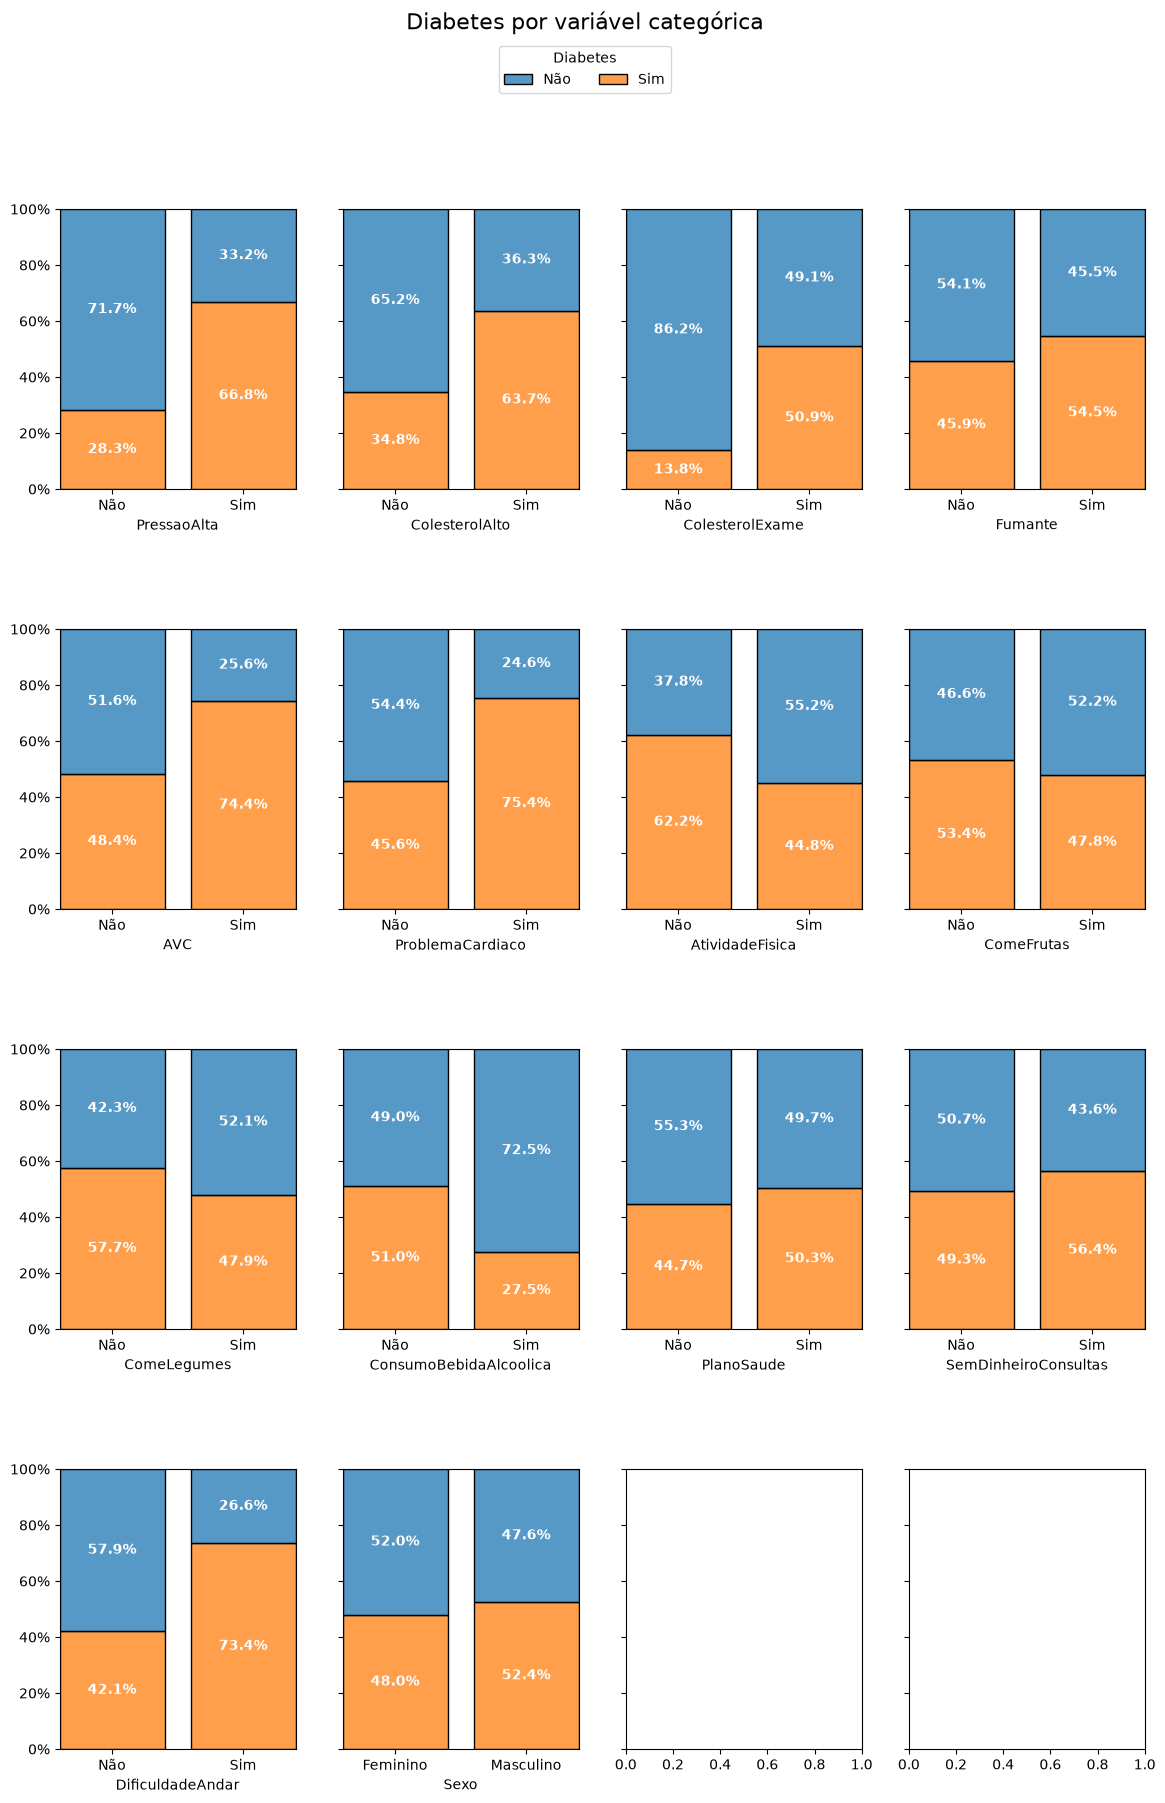

In [4]:
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(14, 20), sharey=True)

for i, coluna in enumerate(colunas_binarias):
    h = sns.histplot(x=coluna, 
        hue=coluna_alvo, 
        data=df_diabetes_tratado, 
        multiple='fill', 
        ax=axs.flat[i], 
        stat='percent',
        shrink=0.8)
    h.tick_params(axis='x') 

    h. yaxis.set_major_formatter(PercentFormatter(1))
    h.set_ylabel('')

    for barra in h.containers:
        h.bar_label(barra, label_type=('center'), labels=[f'{parte.get_height():.1%}' for parte in barra ], color='white', weight='bold')

    legend = h.get_legend()
    legend.remove()

labels = [text.get_text() for text in legend.get_texts()]

fig.legend(handles=legend.legend_handles, labels=labels, loc='upper center', ncols=2, title='Diabetes', bbox_to_anchor=(0.5, 0.965))
fig.suptitle('Diabetes por variável categórica\n\n\n', fontsize=16)

fig.align_labels()

# Aumenta o espaçamento vertical entre as linhas dos gráficos
plt.subplots_adjust(hspace=0.5)

plt.show() 

## Diabetes por variável, com função pronta

A função `plotar_histogramas_preenchidos` (do módulo `graficos.py`, material do curso) encapsula o gráfico anterior. Aqui ela é aplicada às variáveis não binárias, em uma coluna e com os rótulos do eixo x girados em 45°.

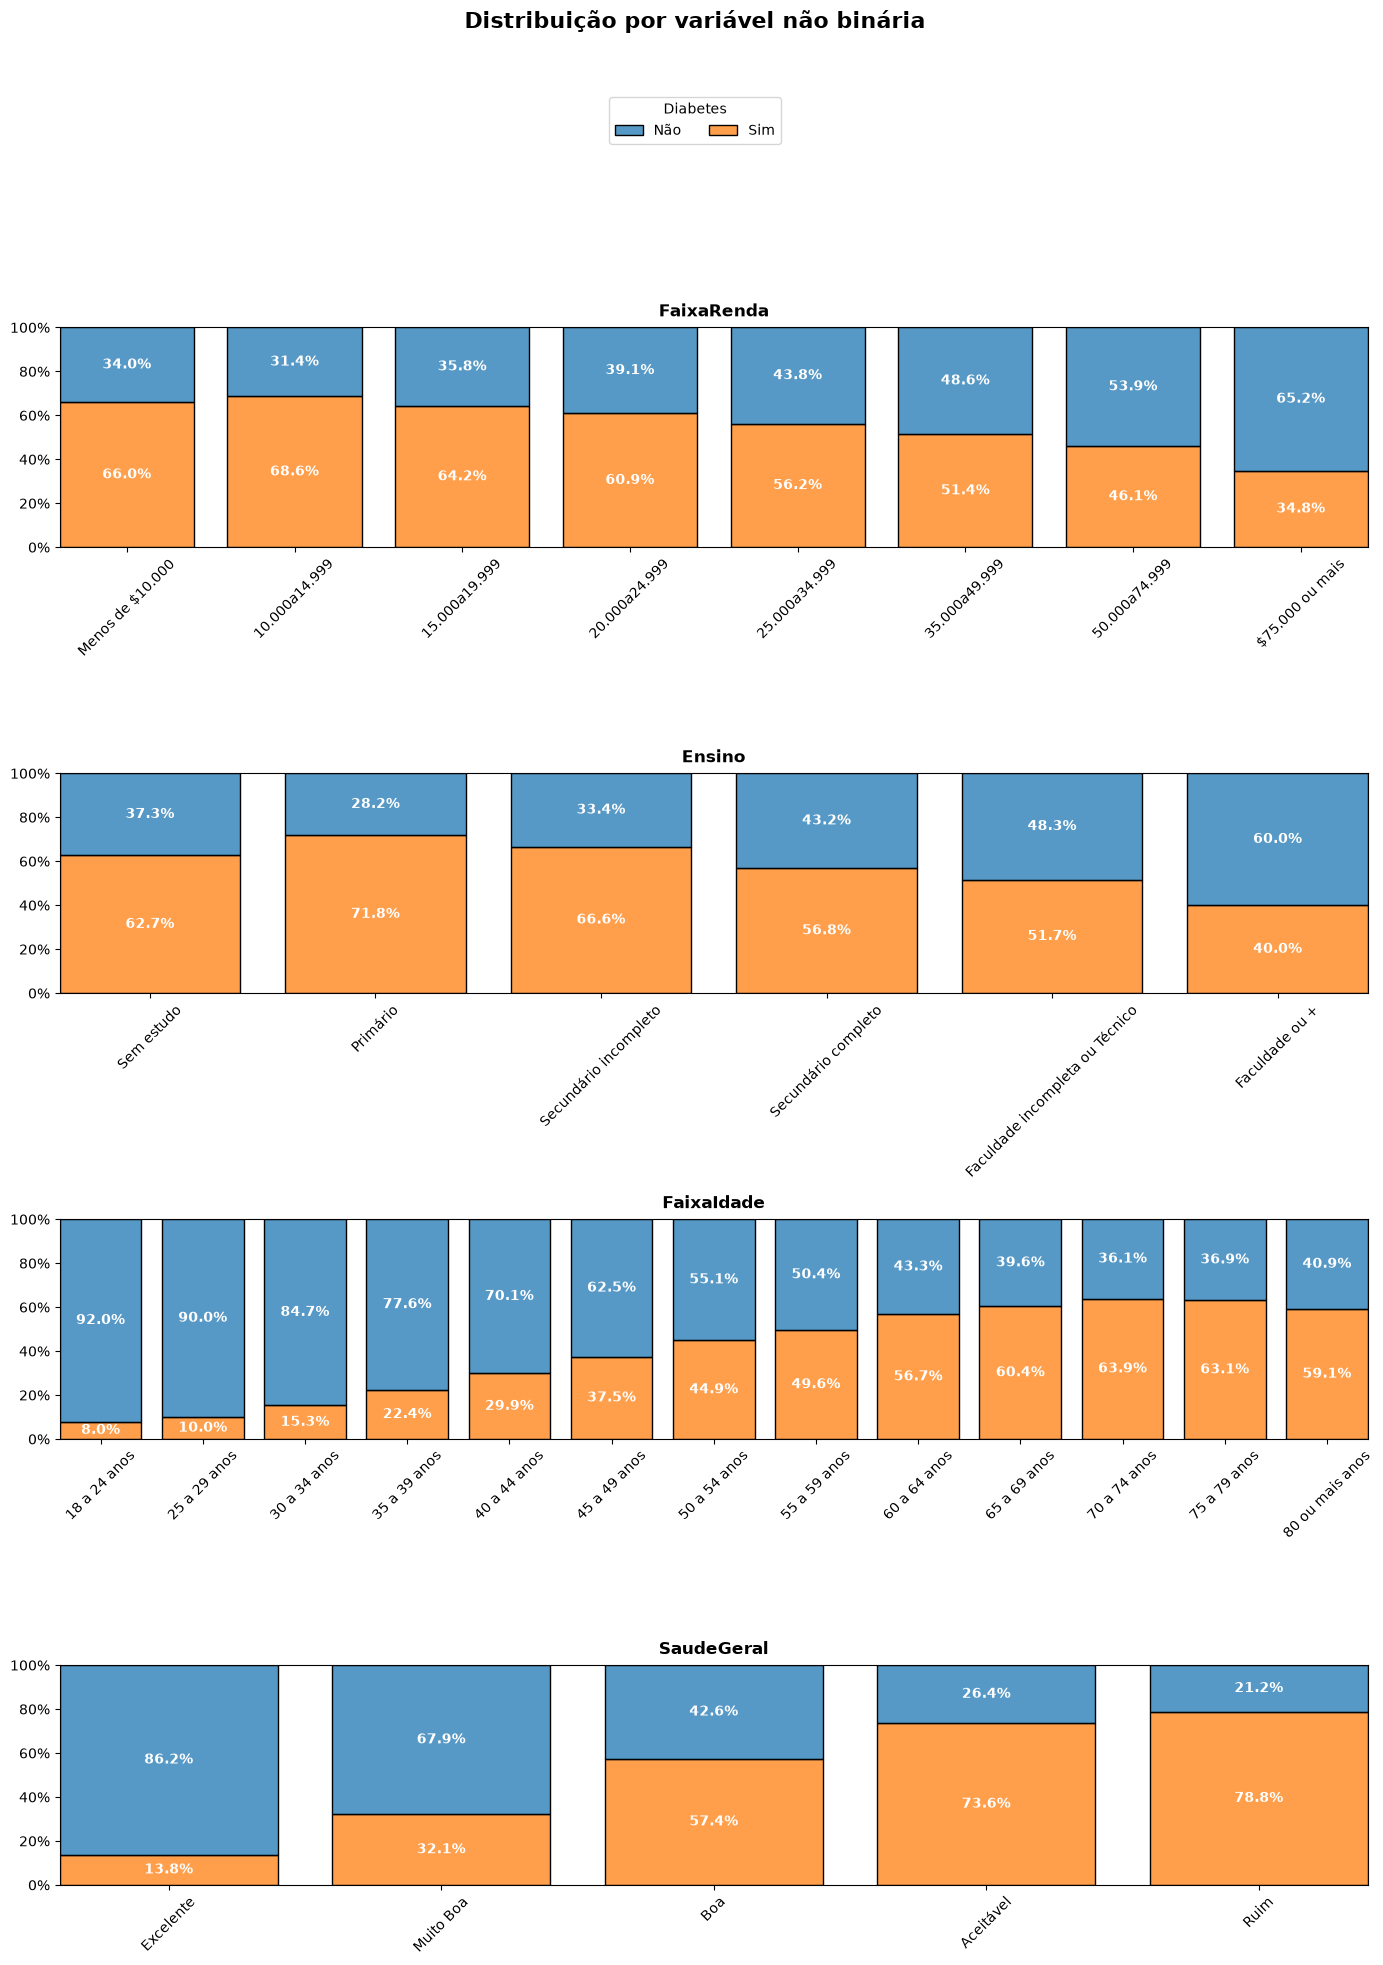

In [5]:
# Ao omitir o figsize, a função ajusta o tamanho exato de acordo com a quantidade de gráficos!
plotar_histogramas_preenchidos(
    data=df_diabetes_tratado,
    colunas=colunas_nao_binarias,
    coluna_alvo=coluna_alvo,
    titulo="Distribuição por variável não binária",
    ncols=1,
    labelrotation=45,
    figsize=(14, 20)
)

A mesma função aplicada às variáveis binárias, agora em 4 colunas e sem rotação dos rótulos.

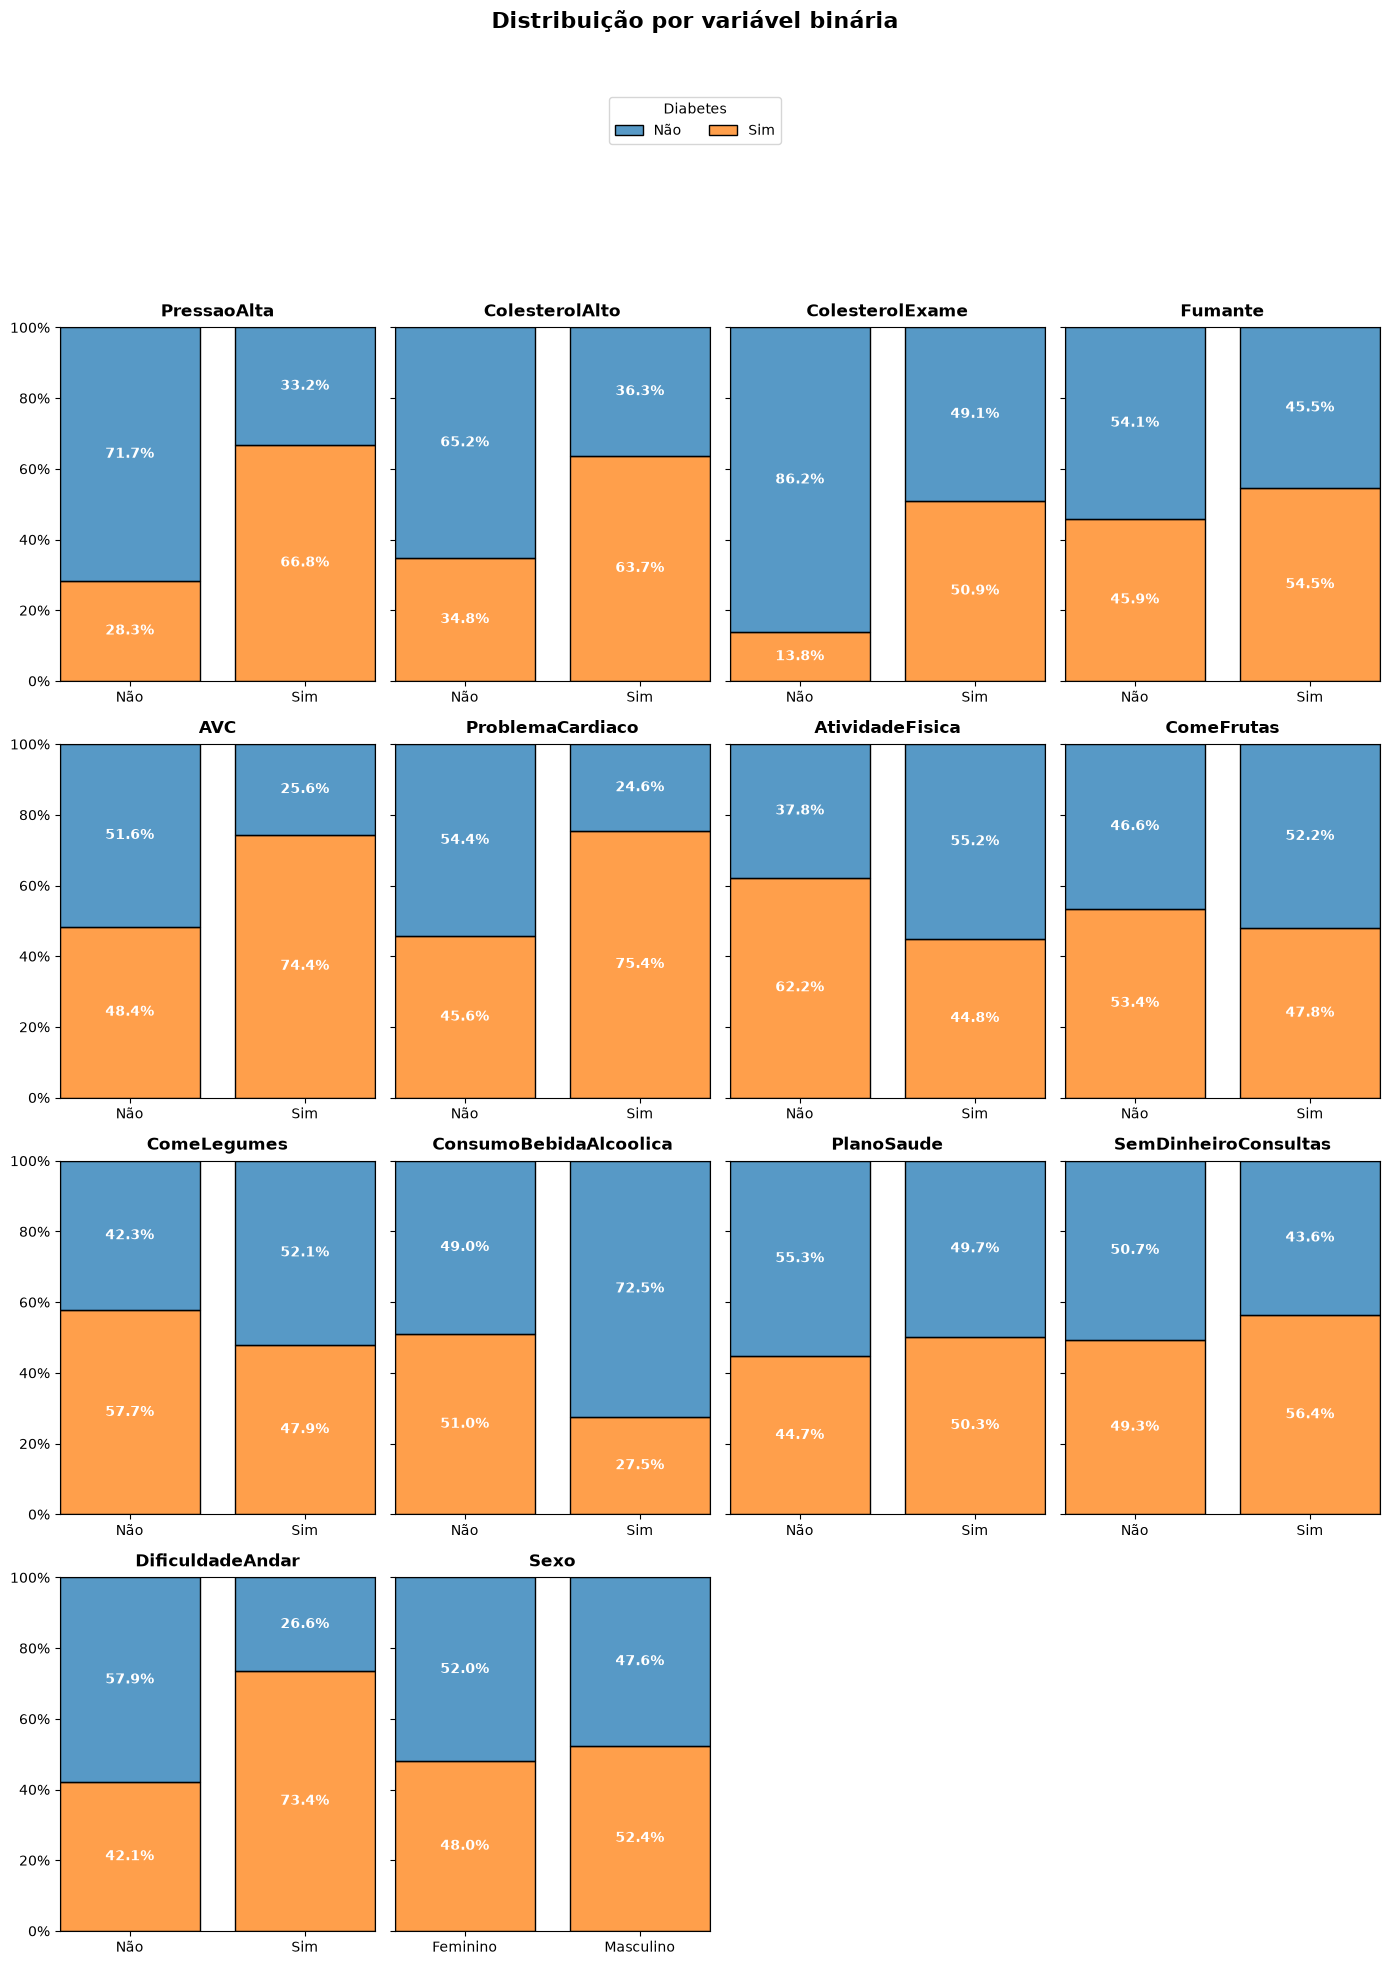

In [6]:
# Ao omitir o figsize, a função ajusta o tamanho exato de acordo com a quantidade de gráficos!
plotar_histogramas_preenchidos(
    data=df_diabetes_tratado,
    colunas=colunas_binarias,
    coluna_alvo=coluna_alvo,
    titulo="Distribuição por variável binária",
    ncols=4,
    labelrotation=0,
    figsize=(14, 20)
)

## Ensino × Saúde Geral e Faixa de Renda

Para cada nível de `Ensino`, mostra a proporção de cada categoria de `SaudeGeral` e de `FaixaRenda`. A legenda de cada gráfico é reposicionada acima da área de plotagem.

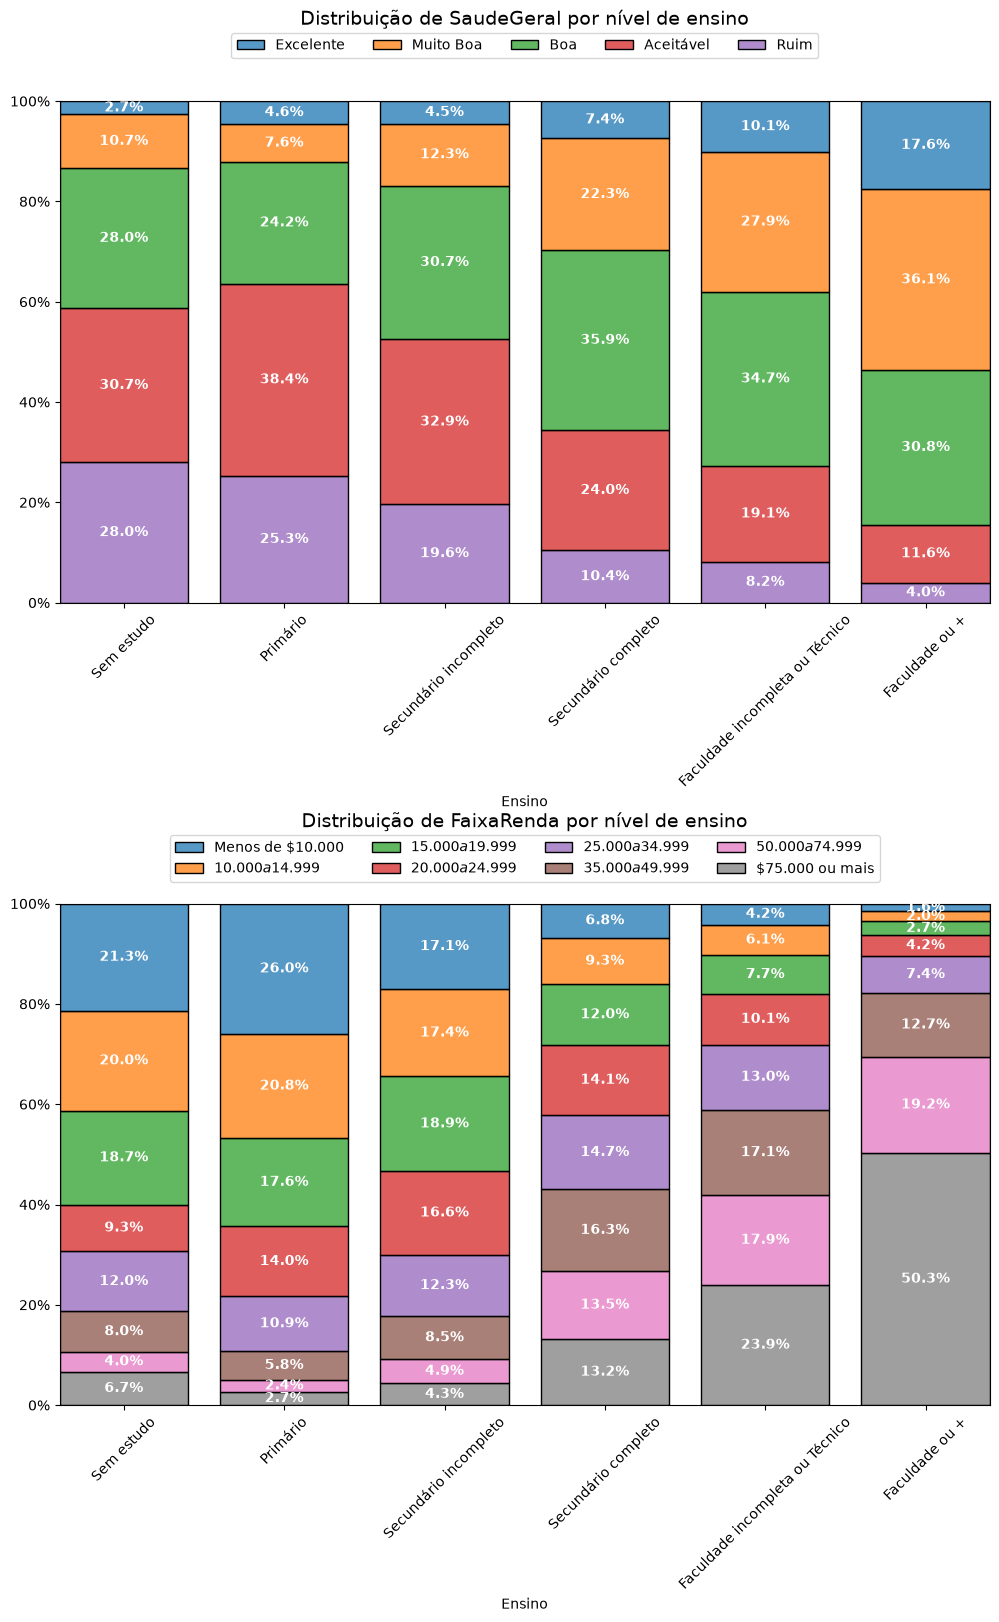

In [7]:
colunas_analise = ["SaudeGeral", "FaixaRenda"]

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(12, 16))

for ax, coluna in zip(axs.flatten(), colunas_analise):
    h = sns.histplot(x="Ensino",
                     hue=coluna,
                     data=df_diabetes_tratado,
                     multiple='fill',
                     ax=ax,
                     stat='percent',
                     shrink=0.8)
    h.tick_params(axis='x', labelrotation=45)

    h.yaxis.set_major_formatter(PercentFormatter(1))
    h.set_ylabel('')

    for bar in h.containers:
        h.bar_label(bar, label_type='center', labels=[f'{b.get_height():.1%}' for b in bar], color='white', weight='bold')

    legend = h.get_legend()

    labels = [text.get_text() for text in legend.get_texts()]

    numero_itens = len(df_diabetes_tratado[coluna].cat.categories)

    ax.legend(
        handles=legend.legend_handles,
        labels=labels,
        loc="upper center",
        ncols=numero_itens if numero_itens <= 6 else min(4, numero_itens),
        bbox_to_anchor=(0.5, 1.15),
    )

    ax.set_title(f"Distribuição de {coluna} por nível de ensino", fontsize=14, pad=55)

plt.subplots_adjust(wspace=0.1, hspace=0.6, top=0.925)

plt.show()

## Tabelas de contingência

Cria um dicionário com a tabela de contingência (`pd.crosstab`) entre `Diabetes` e cada variável categórica. Essas tabelas são a entrada do teste qui-quadrado.

In [8]:
tabelas_contingencia = {}

for coluna in df_diabetes_tratado.select_dtypes("category").columns:
    if coluna != coluna_alvo:
        tabelas_contingencia[coluna] = pd.crosstab(df_diabetes_tratado[coluna_alvo], df_diabetes_tratado[coluna])

Tabelas de proporção por linha (`normalize='index'`), formatadas em porcentagem. Mostram, para cada grupo de `Diabetes`, como se distribuem as categorias de cada variável.

In [9]:
for coluna in df_diabetes_tratado.select_dtypes("category").columns:
    if coluna != coluna_alvo:
        display(pd.crosstab(
            df_diabetes_tratado[coluna_alvo], 
            df_diabetes_tratado[coluna], 
            margins=True, 
            normalize='index'
        ).style.format("{:.2%}"))

PressaoAlta,Não,Sim
Diabetes,,
Não,62.58%,37.42%
Sim,24.73%,75.27%
All,43.65%,56.35%


ColesterolAlto,Não,Sim
Diabetes,,
Não,61.87%,38.13%
Sim,32.99%,67.01%
All,47.43%,52.57%


ColesterolExame,Não,Sim
Diabetes,,
Não,4.27%,95.73%
Sim,0.68%,99.32%
All,2.47%,97.53%


Fumante,Não,Sim
Diabetes,,
Não,56.77%,43.23%
Sim,48.18%,51.82%
All,52.47%,47.53%


AVC,Não,Sim
Diabetes,,
Não,96.81%,3.19%
Sim,90.75%,9.25%
All,93.78%,6.22%


ProblemaCardiaco,Não,Sim
Diabetes,,
Não,92.73%,7.27%
Sim,77.71%,22.29%
All,85.22%,14.78%


... (8 outputs left out)

Sexo,Feminino,Masculino
Diabetes,,
Não,56.51%,43.49%
Sim,52.09%,47.91%
All,54.30%,45.70%


FaixaIdade,18 a 24 anos,25 a 29 anos,30 a 34 anos,35 a 39 anos,40 a 44 anos,45 a 49 anos,50 a 54 anos,55 a 59 anos,60 a 64 anos,65 a 69 anos,70 a 74 anos,75 a 79 anos,80 ou mais anos
Diabetes,,,,,,,,,,,,,
Não,2.55%,3.55%,4.91%,6.13%,6.99%,8.22%,10.71%,12.28%,12.39%,12.16%,8.21%,5.63%,6.27%
Sim,0.22%,0.40%,0.89%,1.77%,2.97%,4.93%,8.74%,12.06%,16.22%,18.55%,14.54%,9.63%,9.08%
All,1.38%,1.97%,2.90%,3.95%,4.98%,6.58%,9.72%,12.17%,14.30%,15.36%,11.38%,7.63%,7.68%


Ensino,Sem estudo,Primário,Secundário incompleto,Secundário completo,Faculdade incompleta ou Técnico,Faculdade ou +
Diabetes,,,,,,
Não,0.08%,1.31%,3.26%,23.78%,27.38%,44.19%
Sim,0.13%,3.35%,6.50%,31.31%,29.29%,29.42%
All,0.11%,2.33%,4.88%,27.55%,28.33%,36.81%


FaixaRenda,Menos de $10.000,$10.000 a $14.999,$15.000 a $19.999,$20.000 a $24.999,$25.000 a $34.999,$35.000 a $49.999,$50.000 a $74.999,$75.000 ou mais
Diabetes,,,,,,,,
Não,3.47%,3.99%,5.63%,7.37%,9.92%,14.13%,17.43%,38.06%
Sim,6.74%,8.73%,10.09%,11.47%,12.74%,14.97%,14.90%,20.36%
All,5.11%,6.36%,7.86%,9.42%,11.33%,14.55%,16.16%,29.21%


## Teste qui-quadrado de independência

Para cada variável, testa a hipótese nula de que ela é independente de `Diabetes`.

In [10]:
for coluna, tabela in tabelas_contingencia.items():
    chi2, pvalue, _, _ = chi2_contingency(tabela)
    print(f"{coluna} - {chi2=} - {pvalue=}")

PressaoAlta - chi2=np.float64(10287.972984997781) - pvalue=np.float64(0.0)
ColesterolAlto - chi2=np.float64(5911.8066998822505) - pvalue=np.float64(0.0)
ColesterolExame - chi2=np.float64(939.6317718798653) - pvalue=np.float64(2.3798712773419562e-206)
Fumante - chi2=np.float64(522.4810772937883) - pvalue=np.float64(1.2211053080400827e-115)
AVC - chi2=np.float64(1111.0793074560897) - pvalue=np.float64(1.290837098922016e-243)
ProblemaCardiaco - chi2=np.float64(3161.7202445322782) - pvalue=np.float64(0.0)
AtividadeFisica - chi2=np.float64(1778.9607035956992) - pvalue=np.float64(0.0)
ComeFrutas - chi2=np.float64(206.50090830615105) - pvalue=np.float64(7.967064756507964e-47)
ComeLegumes - chi2=np.float64(444.0806516898606) - pvalue=np.float64(1.4007103685991128e-98)
ConsumoBebidaAlcoolica - chi2=np.float64(635.0865339749427) - pvalue=np.float64(3.9133962745676324e-140)
PlanoSaude - chi2=np.float64(37.79561046998934) - pvalue=np.float64(7.855833890083924e-10)
SemDinheiroConsultas - chi2=np.fl

Todos os p-valores são muito menores que 0,05 (o maior é cerca de 8e-10, em `PlanoSaude`), então rejeitamos a independência entre `Diabetes` e todas as variáveis. As associações mais fortes pela estatística qui-quadrado são `SaudeGeral` (cerca de 12.304) e `PressaoAlta` (cerca de 10.288). Com tantos registros, o p-valor sozinho quase sempre rejeita, então vale comparar o tamanho do efeito (a estatística) entre as variáveis.

## Correlação de Spearman entre variáveis categóricas

Cada categoria é convertida para seu código numérico (`cat.codes`) e depois calculamos a correlação de Spearman. Nas variáveis ordinais o código respeita a ordem das categorias. Nas binárias a codificação 0/1 é arbitrária, mas a magnitude da correlação continua informativa.

In [11]:
resultados_correlacao = df_diabetes_tratado.select_dtypes("category").apply(lambda coluna: coluna.cat.codes).corr(method='spearman', numeric_only=False)

resultados_correlacao

,Diabetes,PressaoAlta,ColesterolAlto,ColesterolExame,Fumante,AVC,ProblemaCardiaco,AtividadeFisica,ComeFrutas,ComeLegumes,ConsumoBebidaAlcoolica,PlanoSaude,SemDinheiroConsultas,SaudeGeral,DificuldadeAndar,Sexo,FaixaIdade,Ensino,FaixaRenda
Diabetes,1.000000,0.381516,0.289213,0.115382,0.085999,0.125427,0.211523,-0.158666,-0.054077,-0.079293,-0.094853,0.023191,0.040977,0.414259,0.272646,0.044413,0.261620,-0.169926,-0.232529
PressaoAlta,0.381516,1.000000,0.316515,0.103283,0.087438,0.129060,0.210750,-0.136102,-0.040852,-0.066624,-0.027030,0.035764,0.026517,0.324038,0.234784,0.040819,0.322180,-0.143543,-0.196896
ColesterolAlto,0.289213,0.316515,1.000000,0.085981,0.093398,0.099786,0.181187,-0.090453,-0.047384,-0.042836,-0.025443,0.031532,0.033199,0.239138,0.162043,0.017324,0.217974,-0.083177,-0.110289
ColesterolExame,0.115382,0.103283,0.085981,1.000000,-0.004331,0.022529,0.043497,-0.008249,0.017384,0.000349,-0.027146,0.106800,-0.062669,0.060257,0.044430,-0.007991,0.099208,-0.007693,0.007271
Fumante,0.085999,0.087438,0.093398,-0.004331,1.000000,0.064658,0.124418,-0.079823,-0.074811,-0.029926,0.077835,-0.012939,0.035799,0.149960,0.119789,0.112125,0.098822,-0.152918,-0.112241
AVC,0.125427,0.129060,0.099786,0.022529,0.064658,1.000000,0.223394,-0.079985,-0.008996,-0.047601,-0.023395,0.006484,0.036198,0.182517,0.192266,0.003822,0.123544,-0.071889,-0.134487
ProblemaCardiaco,0.211523,0.210750,0.181187,0.043497,0.124418,0.223394,1.000000,-0.098223,-0.019436,-0.036315,-0.037130,0.015687,0.036029,0.268815,0.232611,0.098161,0.225231,-0.093727,-0.148924
AtividadeFisica,-0.158666,-0.136102,-0.090453,-0.008249,-0.079823,-0.079985,-0.098223,1.000000,0.133813,0.149322,0.019111,0.027089,-0.063302,-0.270967,-0.276868,0.051753,-0.092685,0.193831,0.202370
ComeFrutas,-0.054077,-0.040852,-0.047384,0.017384,-0.074811,-0.008996,-0.019436,0.133813,1.000000,0.238605,-0.033246,0.029385,-0.045843,-0.099559,-0.050784,-0.088723,0.067778,0.104653,0.076732
ComeLegumes,-0.079293,-0.066624,-0.042836,0.000349,-0.029926,-0.047601,-0.036315,0.149322,0.238605,1.000000,0.022090,0.029152,-0.037146,-0.117258,-0.084072,-0.052604,-0.017208,0.153539,0.155816


`PressaoAlta` (cerca de 0,38) e `ColesterolAlto` (cerca de 0,29) têm correlação positiva com `Diabetes`, enquanto `AtividadeFisica` tem correlação negativa (cerca de -0,16).

Mapa de calor da matriz de correlação. A máscara `np.triu` esconde o triângulo superior, para que cada par de variáveis apareça uma única vez.

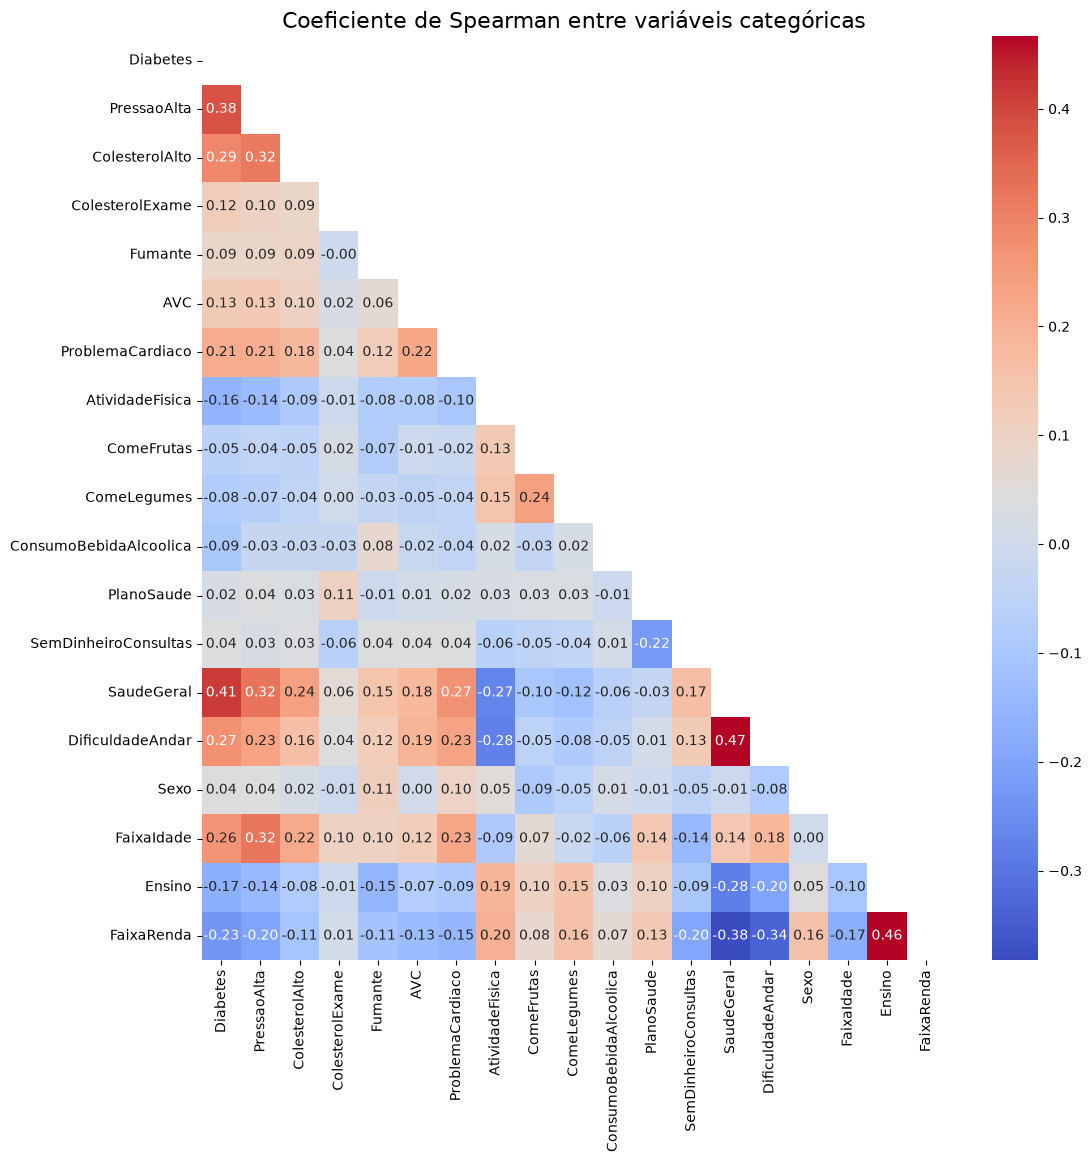

In [12]:
matriz = np.triu(resultados_correlacao)

fig, ax = plt.subplots(figsize=(12, 12))

sns.heatmap(resultados_correlacao, mask=matriz, annot=True, fmt=".2f", ax=ax, cmap="coolwarm")

plt.title("Coeficiente de Spearman entre variáveis categóricas", fontsize=16)

plt.show()